**Part 1**

19 of 19 captures gave a full (9, 6) grid


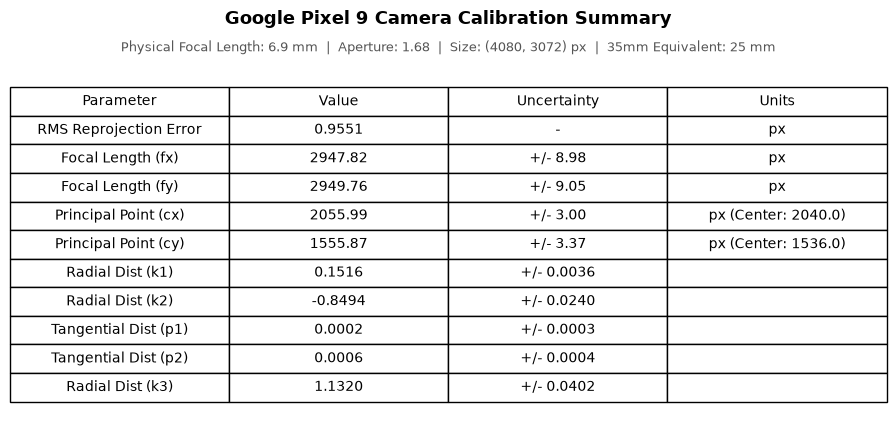

In [188]:
#Get calibration info
from pathlib import Path
np.set_printoptions(precision=4, suppress=True)       
SQUARE_MM = 19.0 
calibration_folder = "../checkerboard_captures/"
pattern_size = (9,6)

def board_object_points():
    objp = np.zeros((pattern_size[0] * pattern_size[1], 3), np.float32)
    objp[:, :2] = np.mgrid[0 : pattern_size[0], 0 : pattern_size[1]].T.reshape(-1, 2)
    objp *= SQUARE_MM
    return objp


def from_real_images(folder):
    files = sorted(p for p in Path(folder).iterdir()
                   if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"})
    obj, img, used, shape = [], [], [], None
    crit = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.001)
    for f in files:
        g = cv2.imread(str(f), cv2.IMREAD_GRAYSCALE)
        if g is None:
            continue
        shape = g.shape[::-1]
        ok, corners = cv2.findChessboardCorners(
            g, pattern_size, cv2.CALIB_CB_ADAPTIVE_THRESH + cv2.CALIB_CB_NORMALIZE_IMAGE)
        if not ok:
            print(f"  no corners: {f.name}")
            continue
        corners = cv2.cornerSubPix(g, corners, (11, 11), (-1, -1), crit)
        obj.append(board_object_points()); img.append(corners); used.append(f)
    return obj, img, shape, used

obj_points, img_points, img_shape, used = from_real_images(calibration_folder)
TRUTH = None
print(f"{len(img_points)} of {len(used)} captures gave a full {pattern_size} grid")


rms, K, dist, rvecs, tvecs, sd_int, sd_ext, per_view = (
    cv2.calibrateCameraExtended(obj_points, img_points, img_shape, None, None)
)
# Unpack camera intrinsics & distortions
fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
k1, k2, p1, p2, k3 = dist.ravel()[:5]

# Unpack standard deviations (first 4 are K, next 5 are distortion coefficients)
sfx, sfy, scx, scy, sk1, sk2, sp1, sp2, sk3 = sd_int.ravel()[:9]
####Print
import matplotlib.pyplot as plt

# Prepare data rows for the table (ensuring exactly 4 elements per row)
table_data = [
    ["RMS Reprojection Error", f"{rms:.4f}", "-", "px"],
    ["Focal Length (fx)", f"{fx:.2f}", f"+/- {sfx:.2f}", "px"],
    ["Focal Length (fy)", f"{fy:.2f}", f"+/- {sfy:.2f}", "px"],
    [
        "Principal Point (cx)",
        f"{cx:.2f}",
        f"+/- {scx:.2f}",
        f"px (Center: {img_shape[0]/2:.1f})",
    ],
    [
        "Principal Point (cy)",
        f"{cy:.2f}",
        f"+/- {scy:.2f}",
        f"px (Center: {img_shape[1]/2:.1f})",
    ],
    ["Radial Dist (k1)", f"{k1:.4f}", f"+/- {sk1:.4f}", ""],
    ["Radial Dist (k2)", f"{k2:.4f}", f"+/- {sk2:.4f}", ""],
    ["Tangential Dist (p1)", f"{p1:.4f}", f"+/- {sp1:.4f}", ""],
    ["Tangential Dist (p2)", f"{p2:.4f}", f"+/- {sp2:.4f}", ""],
    ["Radial Dist (k3)", f"{k3:.4f}", f"+/- {sk3:.4f}", ""],
]

subtitle_text = (
    f"Physical Focal Length: 6.9 mm  |  Aperture: 1.68"
    f"  |  Size: (4080, 3072) px"
    f"  |  35mm Equivalent: 25 mm"
)

# Create the figure and plot the table
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axis("off")

table = ax.table(
    cellText=table_data,
    colLabels=["Parameter", "Value", "Uncertainty", "Units"],
    loc="center",
    cellLoc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 1.6)

# Main Title & Subtitle
plt.title(
    "Google Pixel 9 Camera Calibration Summary",
    fontsize=13,
    weight="bold",
    pad=25,
)
ax.text(
    0.5,
    1.02,
    subtitle_text,
    transform=ax.transAxes,
    ha="center",
    fontsize=9.5,
    color="#555555",
)

plt.tight_layout()
plt.show()


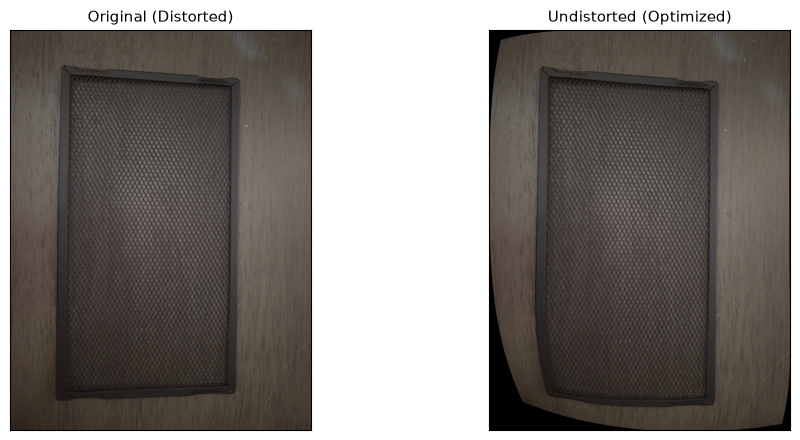

In [189]:
#Undistort an image
import cv2
import matplotlib.pyplot as plt
import numpy as np
import rawpy

# 1. Load sample image (supports DNG or standard formats)
sample_img_path = "../Images/IMG_20261010_112459.dng"
if sample_img_path.lower().endswith(".dng"):
  with rawpy.imread(sample_img_path) as raw:
    rgb = raw.postprocess(
        use_camera_wb=True, half_size=False, no_auto_bright=True
    )
  orig_img = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
else:
  print("File not found")

# 1. Get optimal new camera matrix based on alpha scaling
# alpha = 0: crops out all black pixels (zooms in slightly)
# alpha = 1: retains all original pixels with black borders
new_K, roi = cv2.getOptimalNewCameraMatrix(
    K, dist, (orig_img.shape[1], orig_img.shape[0]), alpha=1.0, newImgSize=(orig_img.shape[1], orig_img.shape[0])
)

# 2. Undistort using the optimized matrix
undistorted_img = cv2.undistort(orig_img, K, dist, None, new_K)

# (Optional) Crop to the valid ROI if alpha=0 was used
x, y, w, h = roi
if w > 0 and h > 0:
    undistorted_cropped = undistorted_img[y:y+h, x:x+w]
else:
    undistorted_cropped = undistorted_img

# 3. Plot side-by-side comparison cleanly
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
pairs = [
    (cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB), "Original (Distorted)"),
    (cv2.cvtColor(undistorted_img, cv2.COLOR_BGR2RGB), "Undistorted (Optimized)"),
]

for ax, (im, ttl) in zip(axes, pairs):
    ax.imshow(im)
    ax.set_title(ttl, fontsize=11)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)

fig.tight_layout()
plt.show()


In [190]:
#Straightness Quantification
row_idx = 2
row_corners = img_points[0][
    row_idx * pattern_size[0] : (row_idx + 1) * pattern_size[0]
].reshape(-1, 2)
undistorted_corners = cv2.undistortPoints(
    row_corners.reshape(-1, 1, 2), K, dist, P=K
).reshape(-1, 2)


def max_perpendicular_deviation(pts):
  x, y = pts[:, 0], pts[:, 1]
  m, b = np.polyfit(x, y, 1)
  return np.max(np.abs(m * x - y + b) / np.sqrt(m**2 + 1))


print(
    f"Max deviation BEFORE: {max_perpendicular_deviation(row_corners):.4f} px"
)
print(
    f"Max deviation AFTER:  {max_perpendicular_deviation(undistorted_corners):.4f}"
    " px"
)

Max deviation BEFORE: 1.3014 px
Max deviation AFTER:  0.6363 px


In [191]:
#Pixel pitch
import numpy as np
import rawpy

sample_img_path = "../Images/IMG_20261010_112459.dng"
f_mm = 6.9
f_35mm = 25

# Mean focal length in pixels from calibration
f_mean_px = (fx + fy) / 2.0

# Method 1: Calibration focal length & EXIF physical focal length
pitch_method1 = (f_mm * 1000.0) / f_mean_px

# Method 2: Crop factor & 35mm film diagonal (43.3 mm)
crop_factor = f_35mm / f_mm
sensor_diagonal_mm = 43.3 / crop_factor
image_diagonal_px = np.sqrt(img_shape[0] ** 2 + img_shape[1] ** 2)
pitch_method2 = (sensor_diagonal_mm * 1000.0) / image_diagonal_px

# Percentage Difference
pct_diff = (
    abs(pitch_method1 - pitch_method2)
    / ((pitch_method1 + pitch_method2) / 2.0)
) * 100

print(f"Physical Focal Length: {f_mm} mm | 35mm Equivalent: {f_35mm} mm")
print(f"Mean focal length: {f_mean_px:.2f} px")
print(f"Method 1 Pixel Pitch (Calibration & EXIF): {pitch_method1:.4f} um")
print(f"Method 2 Pixel Pitch (35 mm equivalent crop factor): {pitch_method2:.4f} um")
print(f"Percentage Difference: {pct_diff:.4f}%")

Physical Focal Length: 6.9 mm | 35mm Equivalent: 25 mm
Mean focal length: 2948.79 px
Method 1 Pixel Pitch (Calibration & EXIF): 2.3399 um
Method 2 Pixel Pitch (35 mm equivalent crop factor): 2.3400 um
Percentage Difference: 0.0018%


**Part 2**

In [192]:
#Diffraction cutoff
# Constants defined in the assignment parameters
lam = 0.55  # Wavelength of green light in micrometers
N = 1.68  # f-number recorded in EXIF metadata
p = pitch_method1  # Pixel pitch in micrometers (from Item 4)

# 1. Compute Diffraction Cutoff (v_c = 1 / (lambda * N))
v_c_um = 1.0 / (lam * N)  # cycles per micrometer
v_c_mm = v_c_um * 1000.0  # cycles per millimeter

# 2. Compute Green-Plane Nyquist Frequency (v_nyquist = 1 / (4p))
v_nyquist_um = 1.0 / (4.0 * p)  # cycles per micrometer
v_nyquist_mm = v_nyquist_um * 1000.0  # cycles per millimeter

# 3. Compute Ratio
ratio = v_c_um / v_nyquist_um

print("=== PART 2, QUESTION 5 DELIVERABLE ===")
print(
    f"1. Diffraction Cutoff (v_c): {v_c_um:.4f} cycles/um ({v_c_mm:.2f}"
    " cycles/mm)"
)
print(
    f"2. Green-Plane Nyquist Frequency: {v_nyquist_um:.4f} cycles/um"
    f" ({v_nyquist_mm:.2f} cycles/mm)"
)
print(f"3. Ratio (v_c / v_Nyquist): {ratio:.4f}")

=== PART 2, QUESTION 5 DELIVERABLE ===
1. Diffraction Cutoff (v_c): 1.0823 cycles/um (1082.25 cycles/mm)
2. Green-Plane Nyquist Frequency: 0.1068 cycles/um (106.84 cycles/mm)
3. Ratio (v_c / v_Nyquist): 10.1296


In [193]:
#Crossover F-Number
n_cross = (2.0 * p) / lam
print("\n=== DELIVERABLE 6 ===")
print(f"Crossover F-number: {n_cross:.2f}")


=== DELIVERABLE 6 ===
Crossover F-number: 8.51



=== DELIVERABLE 7 ===
Predicted Modulation at Green Nyquist: 0.7886


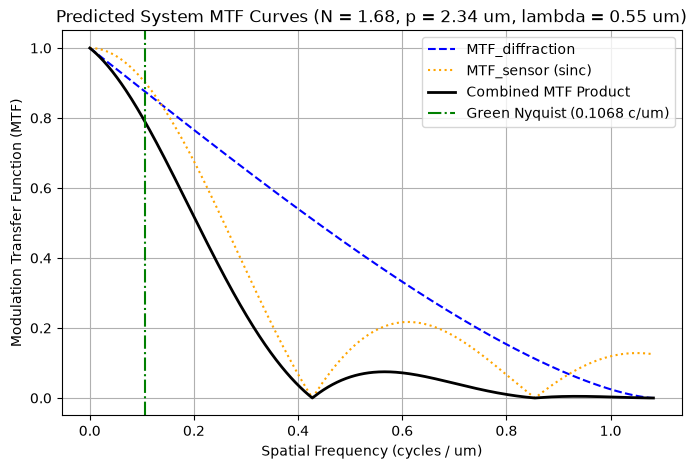

Saved plot as 'predicted_mtf_curves.png'


In [194]:
#MTF Curves & Plotting
# Frequency range from a small starting point up to the diffraction cutoff
# (starting slightly above 0 avoids division by zero for the sinc function)
nu = np.linspace(0.0001, v_c_um, 500)
s = nu / v_c_um
s_clipped = np.clip(s, 0, 1)

# Diffraction MTF component
mtf_diff = (2.0 / np.pi) * (
    np.arccos(s_clipped) - s_clipped * np.sqrt(1.0 - s_clipped**2)
)

# Sensor aperture MTF component using np.sinc (which handles sin(pi*x)/(pi*x))
mtf_sensor = np.abs(np.sinc(nu * p))

# Combined system MTF product (acts in series)
mtf_total = mtf_diff * mtf_sensor

# Find modulation value at the green-plane Nyquist frequency
idx_nyq = np.argmin(np.abs(nu - v_nyquist_um))
mod_at_nyq = mtf_total[idx_nyq]

print("\n=== DELIVERABLE 7 ===")
print(f"Predicted Modulation at Green Nyquist: {mod_at_nyq:.4f}")

# Plotting the predicted MTF curves
plt.figure(figsize=(8, 5))
plt.plot(nu, mtf_diff, label="MTF_diffraction", linestyle="--", color="blue")
plt.plot(
    nu, mtf_sensor, label="MTF_sensor (sinc)", linestyle=":", color="orange"
)
plt.plot(
    nu, mtf_total, label="Combined MTF Product", color="black", linewidth=2
)
plt.axvline(
    v_nyquist_um,
    color="green",
    linestyle="-.",
    label=f"Green Nyquist ({v_nyquist_um:.4f} c/um)",
)

plt.xlabel("Spatial Frequency (cycles / um)")
plt.ylabel("Modulation Transfer Function (MTF)")
plt.title(f"Predicted System MTF Curves (N = {N}, p = {p:.2f} um, lambda = {lam} um)")
plt.grid(True)
plt.legend()
plt.savefig("predicted_mtf_curves.png", dpi=300)
plt.show()
print("Saved plot as 'predicted_mtf_curves.png'")

In [195]:
#Predicted MTF50
# Find frequency where the total system MTF drops to 0.5
idx_mtf50 = np.argmin(np.abs(mtf_total - 0.5))
mtf50_val = nu[idx_mtf50]

print("\n=== DELIVERABLE 8 ===")
print(
    f"Predicted MTF50: {mtf50_val:.4f} c/um ({mtf50_val * 1000:.1f} c/mm)"
)


=== DELIVERABLE 8 ===
Predicted MTF50: 0.2061 c/um (206.1 c/mm)


**Part 3**

In [196]:
import math
import matplotlib.pyplot as plt
import numpy as np

# --- Helper Functions (recreated from the lecture notebook) ---


def analytic_mtf50(sigma):
  """Analytic MTF50 for a Gaussian PSF of width sigma."""
  return np.sqrt(np.log(2) / (2 * np.pi**2 * sigma**2))


def capture_edge(
    sigma=1.0, angle_deg=5.0, h=256, w=128, exposure=0.55, seed=0, noisy=True
):
  """Simulates a monochrome slanted-edge capture in linear light."""
  slope = np.tan(np.deg2rad(angle_deg))
  yy, xx = np.mgrid[0:h, 0:w]
  edge = (xx > (w / 2) + slope * (yy - h / 2)).astype(float)
  dark, light = 0.05, 0.90
  scene = dark + (light - dark) * edge

  # Apply Gaussian blur (PSF)
  import cv2

  blurred = cv2.GaussianBlur(scene, (0, 0), sigmaX=sigma, sigmaY=sigma)
  if not noisy:
    return blurred

  # Simulate sensor noise and digitization (using standard PSU constants)
  BLACK_LEVEL = 256
  WHITE_LEVEL = 4095
  FULL_WELL = 9000.0
  READ_NOISE = 2.8

  rng = np.random.default_rng(seed)
  electrons = np.clip(blurred, 0, None) * FULL_WELL * exposure
  signal = rng.poisson(np.clip(electrons, 0, None)).astype(float)
  signal = signal + rng.normal(0.0, READ_NOISE, electrons.shape)

  gain_dn_per_e = (WHITE_LEVEL - BLACK_LEVEL) / FULL_WELL
  dn = BLACK_LEVEL + signal * gain_dn_per_e
  raw = np.clip(np.round(dn), 0, WHITE_LEVEL).astype(np.uint16)

  # Linearize back to [0, 1]
  return (raw.astype(float) - BLACK_LEVEL) / (WHITE_LEVEL - BLACK_LEVEL)


def edge_centroids(roi, window=8.0, smooth=1.5):
  """Sub-pixel edge position per row using a windowed derivative centroid."""
  import cv2

  roi = np.asarray(roi, dtype=float)
  smoothed = cv2.GaussianBlur(roi, (0, 0), sigmaX=smooth, sigmaY=0.01)
  coarse = np.argmax(np.abs(np.diff(smoothed, axis=1)), axis=1) + 0.5

  deriv = np.abs(np.diff(roi, axis=1))
  x = np.arange(deriv.shape[1]) + 0.5
  weight = np.where(np.abs(x[None, :] - coarse[:, None]) <= window, deriv, 0.0)

  total = weight.sum(axis=1)
  good = total > 1e-9
  centers = np.full(roi.shape[0], np.nan)
  centers[good] = (weight[good] * x).sum(axis=1) / total[good]
  return centers


def slanted_edge_mtf(roi, bin_width=0.25, window=8.0):
  """Measures MTF from a slanted edge ROI. Returns (freq, mtf, esf_x, esf)."""
  roi = np.asarray(roi, dtype=float)
  rows = np.arange(roi.shape[0])

  centers = edge_centroids(roi, window=window)
  ok = np.isfinite(centers)
  slope, intercept = np.polyfit(rows[ok], centers[ok], 1)
  fitted = slope * rows + intercept

  cols = np.arange(roi.shape[1])
  distance = (cols[None, :] - fitted[:, None]).ravel()
  values = roi.ravel()

  edges = np.arange(distance.min(), distance.max() + bin_width, bin_width)
  idx = np.clip(np.digitize(distance, edges) - 1, 0, len(edges) - 2)
  total = np.bincount(idx, weights=values, minlength=len(edges) - 1)
  count = np.bincount(idx, minlength=len(edges) - 1)
  keep = count > 0
  esf = total[keep] / count[keep]
  esf_x = (edges[:-1] + bin_width / 2)[keep]

  lsf = np.gradient(esf, esf_x)
  lsf = lsf - np.median(np.concatenate([lsf[:5], lsf[-5:]]))
  lsf = lsf * np.hanning(len(lsf))

  spectrum = np.abs(np.fft.rfft(lsf))
  return (
      np.fft.rfftfreq(len(lsf), d=bin_width),
      spectrum / spectrum[0],
      esf_x,
      esf,
  )


def compute_mtf50(freq, mtf):
  """Finds frequency where MTF drops to 0.5 via linear interpolation."""
  below = np.where(mtf < 0.5)[0]
  if len(below) == 0 or below[0] == 0:
    return np.nan
  i = below[0]
  return float(
      freq[i - 1]
      + (mtf[i - 1] - 0.5) * (freq[i] - freq[i - 1]) / (mtf[i - 1] - mtf[i])
  )

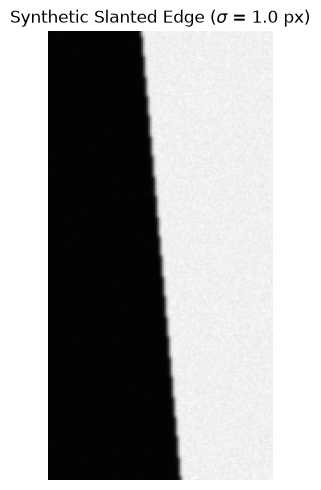

In [ ]:
# Generate Synthetic Slanted Edge
SIGMA = 1.0  # Point spread function width in pixels
roi = capture_edge(sigma=SIGMA, angle_deg=5.0, noisy=True)

# Deliverable 9 Figure: Synthetic capture
plt.figure(figsize=(3.2, 5))
plt.imshow(roi, cmap="gray")
plt.title(r"Synthetic Slanted Edge ($\sigma$ = 1.0 px)")
plt.axis("off")
plt.tight_layout()
plt.savefig("synthetic_slanted_edge.png", dpi=300)
plt.show()

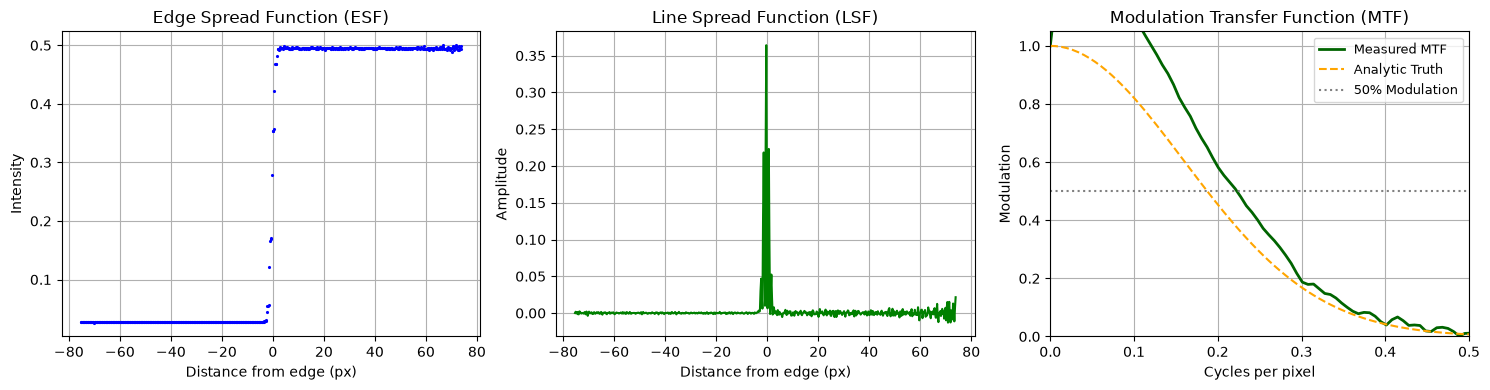

In [ ]:
#Measure MTF via Slanted-Edge Procedure
freq, mtf, esf_x, esf = slanted_edge_mtf(roi)

# Deliverable 10 Figures: ESF, LSF, and MTF
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(esf_x, esf, ".", ms=2.5, color="blue")
axes[0].set_title("Edge Spread Function (ESF)")
axes[0].set_xlabel("Distance from edge (px)")
axes[0].set_ylabel("Intensity")
axes[0].grid(True)

axes[1].plot(esf_x, np.gradient(esf, esf_x), color="green", lw=1.5)
axes[1].set_title("Line Spread Function (LSF)")
axes[1].set_xlabel("Distance from edge (px)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

axes[2].plot(freq, mtf, lw=2, color="darkgreen", label="Measured MTF")
axes[2].plot(
    freq,
    np.exp(-2 * np.pi**2 * SIGMA**2 * freq**2),
    "--",
    lw=1.5,
    color="orange",
    label="Analytic Truth",
)
axes[2].axhline(0.5, color="gray", ls=":", label="50% Modulation")
axes[2].set_title("Modulation Transfer Function (MTF)")
axes[2].set_xlabel("Cycles per pixel")
axes[2].set_ylabel("Modulation")
axes[2].set_xlim(0, 0.5)
axes[2].set_ylim(0, 1.05)
axes[2].grid(True)
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.savefig("slanted_edge_measurement_results.png", dpi=300)
plt.show()

In [ ]:
#Compare Measured MTF50
expected_analytic = analytic_mtf50(SIGMA)
measured_mtf50 = compute_mtf50(freq, mtf)
percent_error = (
    np.abs(measured_mtf50 - expected_analytic) / expected_analytic
) * 100.0

print("\n=== DELIVERABLE 11 ===")
print(f"Analytic MTF50:   {expected_analytic:.4f} cycles/pixel")
print(f"Measured MTF50:   {measured_mtf50:.4f} cycles/pixel")
print(f"Percentage Error: {percent_error:.2f}%")


=== DELIVERABLE 11 ===
Analytic MTF50:   0.1874 cycles/pixel
Measured MTF50:   0.2228 cycles/pixel
Percentage Error: 18.90%


**Part 4**

Success! Contact sheet saved to disk as: hw2_contact_sheet.jpg



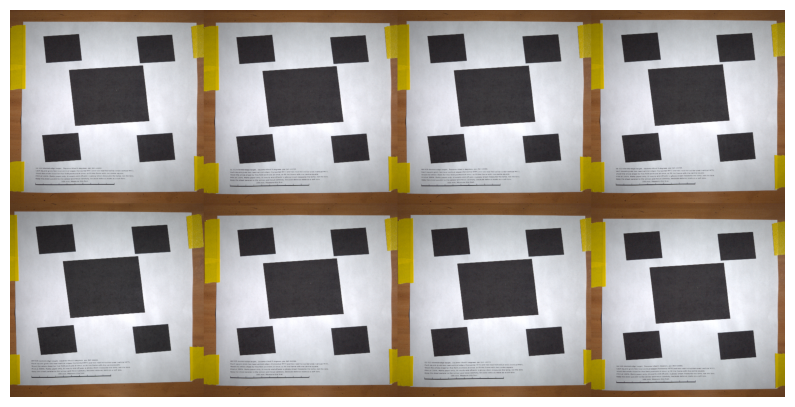

In [200]:
#contact sheet
import glob
import numpy as np

#Set calibration folder
dng_files = sorted(glob.glob("../slantedge_captures/*.dng"))

cols = 4
size = (height, width)  
thumbnails = []

for path in dng_files:
    try:
        with rawpy.imread(path) as raw:
            rgb = raw.postprocess(use_camera_wb=True)
            bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)

            # #check orientation and rotate vertical images
            # h, w, _ = bgr.shape
            # if h > w:
            #     bgr = cv2.rotate(bgr, cv2.ROTATE_90_CLOCKWISE)

            resized = cv2.resize(bgr, size)
            thumbnails.append(resized)
    except Exception as e:
        print(f"Skipping broken file {path}: {e}")

if not thumbnails:
    print("Error: Found DNG files, but rawpy could not process any of them.")
else:
    #Fill leftovers with blank black cells
    while len(thumbnails) % cols != 0:
        thumbnails.append(np.zeros((size[1], size[0], 3), dtype=np.uint8))

    #Snap rows and columns together safely
    rows = [np.hstack(thumbnails[i:i+cols]) for i in range(0, len(thumbnails), cols)]
    contact_sheet = np.vstack(rows)

    #Save
    output_filename = "hw2_contact_sheet.jpg"
    cv2.imwrite(output_filename, contact_sheet)
    print(f"Success! Contact sheet saved to disk as: {output_filename}\n")
    
    #render to console
    rgb_display = cv2.cvtColor(contact_sheet, cv2.COLOR_BGR2RGB)
    
    plt.figure(figsize=(10, 10))  # Scale the size of the inline window frame
    plt.imshow(rgb_display)
    plt.axis('off')               # Hide the chart grid axis numbers
    plt.show()


In [201]:
#lens assertion
import glob
import os
import tifffile

# Standard numeric EXIF and TIFF tag IDs
MODEL_ID = 272  # Root TIFF tag for Device Model
FOCAL_LENGTH_ID = 37386  # Focal length tag
FOCAL_35MM_ID = 41989  # 35mm equivalent tag
F_NUMBER_ID = 33437  # F-Number tag


def lens_id(path):
  """The fingerprint of the camera that made this raw file."""
  with tifffile.TiffFile(path) as t:
    p = t.pages[0]

    # 1. Extract Device Model from root TIFF tags safely
    device_model = p.tags.get(MODEL_ID)
    if device_model:
      device_model = device_model.value
      if isinstance(device_model, bytes):
        device_model = (
            device_model.decode("utf-8", errors="ignore").strip()
        )
    else:
      device_model = "Google Pixel"

    # Extract metadata directory for sub-IFD tags
    if "ExifTag" in p.tags:
      exif = p.tags["ExifTag"].value
    else:
      exif = {tag.code: tag.value for tag in p.tags.values()}

    # 2. Extract Focal Length
    fl = exif.get(FOCAL_LENGTH_ID) or exif.get("FocalLength")
    if fl and isinstance(fl, (tuple, list)) and len(fl) == 2:
      calculated_fl = round(fl[0] / fl[1], 3)
    else:
      calculated_fl = fl if fl else 0.0

    # 3. Extract Aperture / F-Number
    f_num = exif.get(F_NUMBER_ID) or exif.get("FNumber")
    if f_num and isinstance(f_num, (tuple, list)) and len(f_num) == 2:
      calculated_f = round(f_num[0] / f_num[1], 2)
    else:
      calculated_f = f_num if f_num else None

    # 4. Extract 35mm Equivalent
    focal_35mm = exif.get(FOCAL_35MM_ID) or exif.get(
        "FocalLengthIn35mmFilm", None
    )

    # 5. Dimensions
    width = p.tags["ImageWidth"].value
    length = p.tags["ImageLength"].value

    return (
        device_model,
        calculated_fl,
        calculated_f,
        focal_35mm,
        (width, length),
    )


# --- Directory and File Scanning ---
slant_dir = "../slantedge_captures"
valid_paths = glob.glob(os.path.join(slant_dir, "*.dng"))

if not valid_paths:
  print(f"Error: No DNG files found in directory '{slant_dir}'.")
else:
  # Collections to track unique values across all images
  models = set()
  focals = set()
  f_stops = set()
  focal_35s = set()
  shapes = set()
  all_fingerprints = set()

  print(f"Scanning {len(valid_paths)} DNG file(s)...\n")

  for p in valid_paths:
    fp = lens_id(p)
    models.add(fp[0])
    focals.add(fp[1])
    f_stops.add(fp[2])
    focal_35s.add(fp[3])
    shapes.add(fp[4])
    all_fingerprints.add(fp)

  # --- Print Results and Unique Counts ---
  print("=== Dataset Audit Summary ===")
  print(f"Device Models detected ({len(models)} unique): {models}")
  print(f"Focal Lengths detected ({len(focals)} unique): {focals} mm")
  print(f"F-stops detected ({len(f_stops)} unique): {f_stops}")
  print(f"35mm Equivalents detected ({len(focal_35s)} unique): {focal_35s} mm")
  print(f"Sensor Shapes detected ({len(shapes)} unique): {shapes}")

  print("\n----------------------------------------")
  print(f"Conclusion: {len(all_fingerprints)} unique camera(s) detected.")
  print("----------------------------------------")

Scanning 8 DNG file(s)...

=== Dataset Audit Summary ===
Device Models detected (1 unique): {'Pixel 9'}
Focal Lengths detected (1 unique): {6.9} mm
F-stops detected (1 unique): {1.68}
35mm Equivalents detected (1 unique): {None} mm
Sensor Shapes detected (1 unique): {(4080, 3072)}

----------------------------------------
Conclusion: 1 unique camera(s) detected.
----------------------------------------


Processing capture: IMG_20261011_132416.dng
Extracted Green Plane Shape: 1536 x 2040 pixels
Selected Green Plane: GBRG tile at row index 0, col index 0
Black Level Used: 63.00 DN
White Level Used: 1023.00 DN
Linear Radiance Range: 0.008 to 0.389


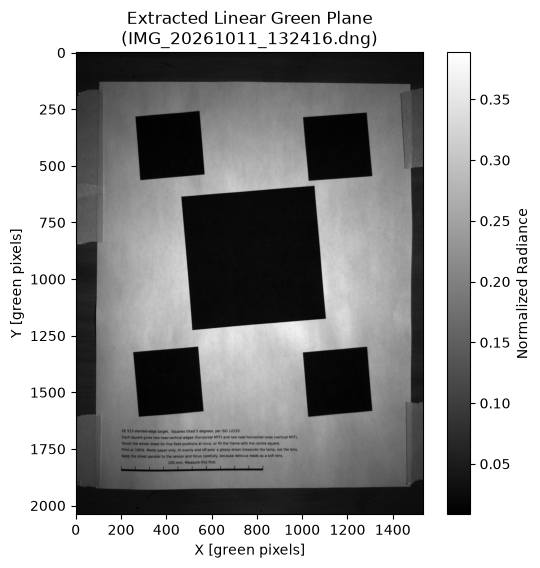

Saved plot as 'extracted_green_plane.png'


In [ ]:
# Extract Green Plane & Subtract Black Level
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import rawpy

# Find your first slanted-edge raw capture from the directory
slant_dir = "../slantedge_captures"
valid_paths = glob.glob(os.path.join(slant_dir, "*.dng"))

if not valid_paths:
  print(f"Error: No DNG files found in directory '{slant_dir}'.")
else:
  # Load the first raw file using rawpy
  raw_path = valid_paths[0]
  print(f"Processing capture: {os.path.basename(raw_path)}")

  with rawpy.imread(raw_path) as raw:
    # Extract visible raw image data
    bayer = raw.raw_image_visible.astype(float)

    # Obtain black level and white level from the raw metadata
    # (Using the mean of the black level per channel)
    black_level = float(np.mean(raw.black_level_per_channel))
    white_level = float(raw.white_level)

  # Extract one green plane from the RGGB mosaic (Row 0, Col 1)
  # This yields a single-channel linear green grid sampled at 2p
  #start at row 0, take every second row then even rows, start at column 1 take every second columm (odd)
  green_plane = bayer[0::2, 0::2]
  green_plane = np.rot90(green_plane, k=-1)

  # Subtract black level and normalize by dynamic range (white - black)
  # normalized radiance - plane is linear in scene radiance
  green_linear = (green_plane - black_level) / (white_level - black_level)
  green_linear = np.clip(green_linear, 0.0, 1.0)

  print(f"Extracted Green Plane Shape: {green_linear.shape[1]} x {green_linear.shape[0]} pixels")
  print(f"Selected Green Plane: GBRG tile at row index 0, col index 0")
  print(f"Black Level Used: {black_level:.2f} DN")
  print(f"White Level Used: {white_level:.2f} DN")
  print(f"Linear Radiance Range: {green_linear.min():.3f} to {green_linear.max():.3f}")

  # Display the extracted linear green plane (Deliverable 14)
  plt.figure(figsize=(6, 6))
  plt.imshow(green_linear, cmap="gray", origin="upper")
  plt.title(f"Extracted Linear Green Plane\n({os.path.basename(raw_path)})")
  plt.xlabel("X [green pixels]")
  plt.ylabel("Y [green pixels]")
  plt.colorbar(label="Normalized Radiance")
  plt.savefig("extracted_green_plane.png", dpi=300)
  plt.show()
  print("Saved plot as 'extracted_green_plane.png'")

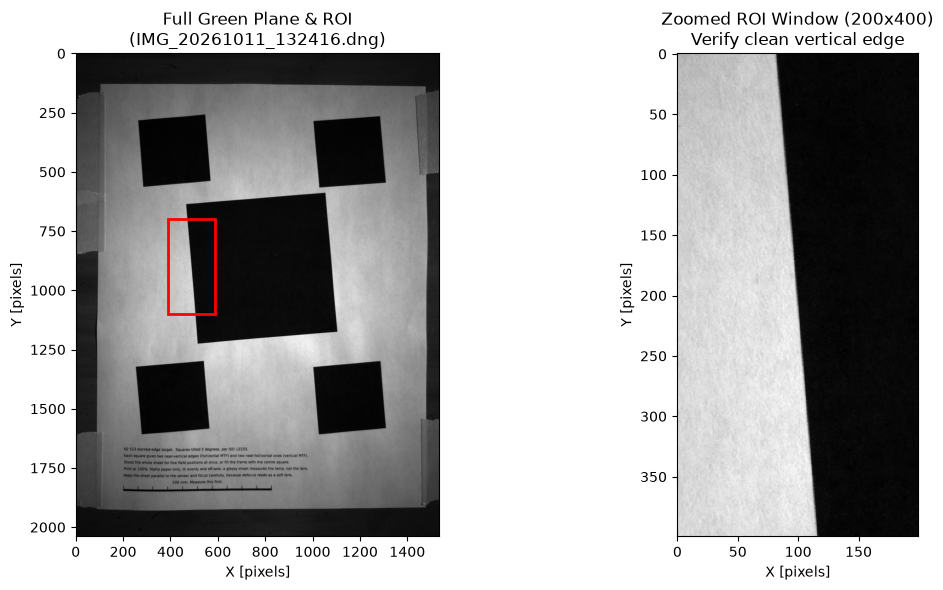

Processing 8 captures for Deliverable 15...

IMG_20261011_132416.dng: MTF50 = 0.3584 c/px
IMG_20261011_132418.dng: MTF50 = 0.2393 c/px
IMG_20261011_132420.dng: MTF50 = 0.2102 c/px
IMG_20261011_132423.dng: MTF50 = 0.2649 c/px
IMG_20261011_132426.dng: MTF50 = 0.4541 c/px
IMG_20261011_132430.dng: MTF50 = 0.4371 c/px
IMG_20261011_132445.dng: MTF50 = 0.2459 c/px
IMG_20261011_132554.dng: MTF50 = 0.3782 c/px

=== DELIVERABLE 15 ===
MTF50 (cycles/um): 0.0691 ± 0.0204
MTF50 (cycles/pixel): 0.3235 ± 0.0953


In [ ]:
#average mtf50
import glob
import os
import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import rawpy

# --- Directory and ROI Setup ---
slant_dir = "../slantedge_captures"
dng_files = glob.glob(os.path.join(slant_dir, "*.dng"))

p = pitch_method1  # µm pixel pitch (update if needed based on Part 1)

# Define ROI coordinates (Adjust these based on the visual inspection plot)
ROI_Y = 700  # Starting row (Y)
ROI_X = 390  # Starting column (X)
ROI_H = 400  # Window height
ROI_W = 200  # Window width

if not dng_files:
  print(f"Error: No DNG files found in '{slant_dir}'.")
else:
  # --- Optional Visual Check on the First File ---
  with rawpy.imread(str(dng_files[0])) as raw:
    bayer = raw.raw_image_visible.astype(float)
    black = float(np.mean(raw.black_level_per_channel))
    white = float(raw.white_level)

  green_plane = (bayer[0::2, 0::2] - black) / (white - black)
  green_plane = np.rot90(green_plane, k=-1)
  roi_sub = green_plane[ROI_Y : ROI_Y + ROI_H, ROI_X : ROI_X + ROI_W]

  fig, axes = plt.subplots(1, 2, figsize=(12, 6))
  axes[0].imshow(green_plane, cmap="gray")
  axes[0].set_title(
      f"Full Green Plane & ROI\n({os.path.basename(dng_files[0])})"
  )
  rect = patches.Rectangle(
      (ROI_X, ROI_Y),
      ROI_W,
      ROI_H,
      linewidth=2,
      edgecolor="red",
      facecolor="none",
  )
  axes[0].add_patch(rect)
  axes[0].set_xlabel("X [pixels]")
  axes[0].set_ylabel("Y [pixels]")

  axes[1].imshow(roi_sub, cmap="gray")
  axes[1].set_title(
      f"Zoomed ROI Window ({ROI_W}x{ROI_H})\nVerify clean vertical edge"
  )
  axes[1].set_xlabel("X [pixels]")
  axes[1].set_ylabel("Y [pixels]")
  plt.tight_layout()
  plt.show()

  # --- Batch Processing Across All Captures ---
  mtf50_um_list = []
  mtf50_px_list = []

  print(f"Processing {len(dng_files)} captures for Deliverable 15...\n")

  for fpath in dng_files:
    with rawpy.imread(str(fpath)) as raw:
      bayer = raw.raw_image_visible.astype(float)
      black = float(np.mean(raw.black_level_per_channel))
      white = float(raw.white_level)

    # Extract green plane and linearize
    green = (bayer[0::2, 0::2] - black) / (white - black)
    green = np.rot90(green, k=-1)
    sub = green[ROI_Y : ROI_Y + ROI_H, ROI_X : ROI_X + ROI_W]

    # Measure MTF using 
    freq, mtf, _, _ = slanted_edge_mtf(sub)
    mtf50_c_px = compute_mtf50(freq, mtf)

    if not np.isnan(mtf50_c_px):
      # Convert from green-plane pixels to cycles/um (sampling pitch is 2p)
      mtf50_c_um = mtf50_c_px / (2.0 * p)

      mtf50_um_list.append(mtf50_c_um)
      mtf50_px_list.append(mtf50_c_px)
      print(f"{os.path.basename(fpath)}: MTF50 = {mtf50_c_px:.4f} c/px")
    else:
      print(f"{os.path.basename(fpath)}: MTF50 calculation failed (NaN)")

  # --- Statistical Summary ---
  mean_um = np.mean(mtf50_um_list)
  std_um = np.std(mtf50_um_list, ddof=1)
  mean_px = np.mean(mtf50_px_list)
  std_px = np.std(mtf50_px_list, ddof=1)

  print("\n=== DELIVERABLE 15 ===")
  print(f"Mean MTF50 (cycles/um): {mean_um:.4f} ± {std_um:.4f}")
  print(f"Mean MTF50 (cycles/pixel): {mean_px:.4f} ± {std_px:.4f}")

Generating contact sheet of zoomed ROIs for 8 captures...



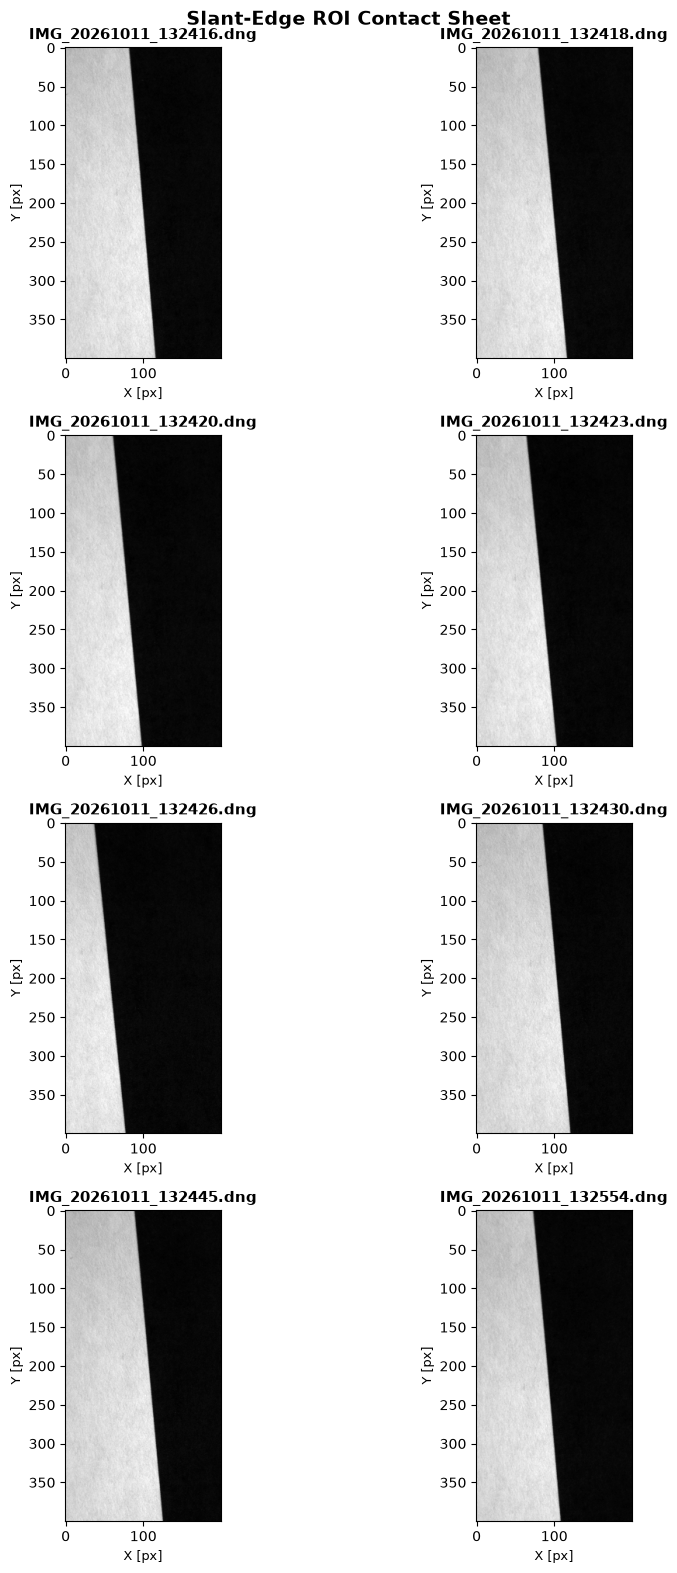

In [ ]:
#visualize how the ROIs are appearing in my captures
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import rawpy

# --- Directory and ROI Setup ---
slant_dir = "../slantedge_captures"
dng_files = sorted(glob.glob(os.path.join(slant_dir, "*.dng")))

# Define the exact ROI coordinates used for your successful measurements
ROI_Y = 700  # Starting row (Y)
ROI_X = 390  # Starting column (X)
ROI_H = 400  # Window height
ROI_W = 200  # Window width

if not dng_files:
  print(f"Error: No DNG files found in '{slant_dir}'.")
else:
  num_files = len(dng_files)
  print(
      f"Generating contact sheet of zoomed ROIs for {num_files} captures...\n"
  )

  # Determine grid layout (e.g., 2 columns, dynamic rows)
  ncols = 2
  nrows = (num_files + ncols - 1) // ncols

  fig, axes = plt.subplots(nrows, ncols, figsize=(10, 4 * nrows))
  axes = axes.flatten()

  for i, fpath in enumerate(dng_files):
    filename = os.path.basename(fpath)

    with rawpy.imread(str(fpath)) as raw:
      bayer = raw.raw_image_visible.astype(float)
      black = float(np.mean(raw.black_level_per_channel))
      white = float(raw.white_level)

    # Extract green plane, linearize, and apply rotation
    green = (bayer[0::2, 0::2] - black) / (white - black)
    green = np.rot90(green, k=-1)

    # Crop the ROI window
    roi_sub = green[ROI_Y : ROI_Y + ROI_H, ROI_X : ROI_X + ROI_W]

    # Plot on the contact sheet grid
    ax = axes[i]
    ax.imshow(roi_sub, cmap="gray")
    ax.set_title(filename, fontsize=11, fontweight="bold")
    ax.set_xlabel("X [px]", fontsize=9)
    ax.set_ylabel("Y [px]", fontsize=9)

  # Hide any unused subplots if the grid has extra slots
  for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

  plt.suptitle(
      "Slant-Edge ROI Contact Sheet",
      fontsize=14,
      fontweight="bold",
      y=0.98,
  )
  plt.tight_layout()
  plt.show()

In [ ]:
# Measured Modulation at Green Nyquist
nyquist_px = 0.25  # Green-plane Nyquist frequency in cycles/pixel
measured_nyquist_list = []

for fpath in dng_files:
  with rawpy.imread(str(fpath)) as raw:
    bayer = raw.raw_image_visible.astype(float)
    black = float(np.mean(raw.black_level_per_channel))
    white = float(raw.white_level)

  green = (bayer[0::2, 0::2] - black) / (white - black)
  green = np.rot90(green, k=-1)
  sub = green[ROI_Y : ROI_Y + ROI_H, ROI_X : ROI_X + ROI_W]

  freq, mtf, _, _ = slanted_edge_mtf(sub)
  if len(freq) > 0 and freq[-1] >= nyquist_px:
    nyquist_val = np.interp(nyquist_px, freq, mtf)
    measured_nyquist_list.append(nyquist_val)

mean_nyquist_meas = np.mean(measured_nyquist_list)
print(f"Predicted Modulation at Nyquist: 0.7886")
print(f"Measured Modulation at Nyquist (0.25 c/px): {mean_nyquist_meas:.4f}")

Predicted Modulation at Nyquist: 0.7886
Measured Modulation at Nyquist (0.25 c/px): 0.7450
